# PHY408 Lab 02: From Collisions to Numbers
### ROOT, the CMS dimuon spectrum and descriptive statistics

**PHY408 Data-Intensive Science** · Xiamen University Malaysia
Week 2, Lesson 2 (hands-on lecture, 2 hours)
**Classroom lesson this week (Lesson 1):** Probability foundations
**Data:** CMS Open Data 2012 DoubleMuParked (NanoAOD-style muon file, streamed); course extract `data/dimuon_extract.npz`; published top-quark mass measurements (PDG compilation)

> **Dimuon thread (Weeks 2-10):** the thread starts here. The extract you build today is the dataset for every lab up to Week 10.

> **Before you start:** work on a *copy* of this notebook inside your personal repository (File → Save As…), so that `git pull` on the course repository never conflicts with your edits.

## The storyline of today

Every part answers one question, and each answer is the input to the next part:

| Part | Question | Tool | Output you keep |
| --- | --- | --- | --- |
| A | How does HEP store and show a distribution? | `TH1F`, `TCanvas`, `TFile` | a histogram saved in a `.root` file |
| B | How do we get a particle's mass from its decay products? | four-vectors (`TLorentzVector`, `PtEtaPhiMVector`) | invariant mass of a toy Z → μμ |
| C | What does real CMS data look like? | `RDataFrame` on CMS Open Data | the dimuon mass spectrum |
| D | How do we avoid rereading terabytes? | `AsNumpy`, `.npz` | **your dimuon extract** |
| E | How do we plot and describe a peak? | Matplotlib, Seaborn, NumPy / SciPy | publication-style figure; Z-peak position and width |
| F | How do we combine many measurements of one number? | pandas, weighted mean, χ² | top-quark mass combination |

The thread in one line: **histogram → four-vector → real events → extract → describe one peak → combine many measurements.**

## Learning objectives

By the end of this lab you should be able to:

1. Create, draw, save and reread ROOT histograms from Python, and explain what the stats box reports
2. Compute the invariant mass of a particle pair and explain why it does not depend on the reference frame
3. Read CMS Open Data with `RDataFrame`, select opposite-sign muon pairs and reconstruct the dimuon spectrum
4. Save a compact analysis extract that later labs reuse
5. Describe a peak with location, spread and shape statistics, and explain why the answers depend on the window you choose
6. Combine independent measurements with an inverse-variance weighted mean and judge their consistency with χ²/ndf

## Lab plan

| Block | Time |
| --- | --- |
| Opening and setup check | 5 min |
| Part A: ROOT histograms and files | 15 min |
| Part B: Four-vectors and invariant mass | 15 min |
| Part C: Real CMS data with RDataFrame | 20 min |
| Part D: Save your dimuon extract | 10 min |
| Part E: Plotting and describing the Z peak | 30 min |
| Part F: Combining measurements: the top-quark mass | 20 min |
| Exit task | 5 min |

## 0. Setup

Run the cell below. If an import fails, check that the `phy408` environment is active (see the course README).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy import stats
from pathlib import Path
import json, sys
rng = np.random.default_rng(408)
OUT = Path('outputs'); OUT.mkdir(exist_ok=True)
DATA = Path('..') / 'data'
plt.rcParams.update({'figure.figsize':(7,4.5), 'axes.grid':True})
try:
    import ROOT
    ROOT.gRandom.SetSeed(408)
    print('ROOT version:', ROOT.gROOT.GetVersion())
except ImportError:
    ROOT = None
    print('ROOT not installed; ROOT-dependent tasks will run in the course environment.')
sys.path.insert(0,str(Path('..').resolve()))
try:
    from common.dimuon import load_dimuon, in_window, PDG_MASS
    dimuon = load_dimuon()
except (ImportError, FileNotFoundError, OSError) as exc:
    # Alternatively read a course extract located beside the notebook / in data/
    candidates=[DATA/'dimuon_extract.npz',Path('data/dimuon_extract.npz'),Path('dimuon_extract.npz')]
    found=next((q for q in candidates if q.exists()), None)
    if found:
        with np.load(found) as f: dimuon={k:f[k] for k in f.files}
        dimuon['source']=str(found)
    else:
        dimuon=None
        print('CMS course extract not available:',exc)
        print('Place the notebook in the course repository with data/dimuon_extract.npz to run Part E.')
if dimuon is not None:
    print(f"{len(dimuon['mass']):,} dimuon candidates ({dimuon.get('source','course extract')})")

ROOT not installed; ROOT-dependent tasks will run in the course environment.
CMS course extract not available: No module named 'common'
Place the notebook in the course repository with data/dimuon_extract.npz to run Part E.


## Part A: ROOT histograms and files (~15 min)

**Question:** how does HEP store and show a distribution?
**Slides:** *What is ROOT?*, *Reading C++*, *TH1F*, *TCanvas*, *TFile I/O*

A `TH1F(name, title, nbins, xmin, xmax)` is a set of bins plus running sums. The title string `"title;x label;y label"` sets the axis labels, and ROOT uses `#mu`, `#sigma` instead of LaTeX backslashes. Values outside `[xmin, xmax)` are **not lost**: they go into the underflow bin (bin 0) and overflow bin (bin `nbins+1`), but they are excluded from the mean and standard deviation shown in the stats box.

In [2]:
if ROOT is not None:
    # Part A: worked example (C++ macro on the slide -> PyROOT)
    h = ROOT.TH1F("h_gaus", "Gaussian;x;Entries / 0.1", 100, -5, 5)
    for x in rng.normal(0, 1, 10_000):
        h.Fill(x)

    c = ROOT.TCanvas("cA", "Part A", 700, 450)
    h.SetLineColor(ROOT.kBlue + 1); h.SetLineWidth(2)
    h.Draw("HIST")
    c.Draw()
    print(f"Entries = {h.GetEntries():.0f}, Mean = {h.GetMean():.3f}, Std Dev = {h.GetStdDev():.3f}")
else:
    print("Worked example 7 requires PyROOT.")

Worked example 7 requires PyROOT.


In [3]:
# ROOT excludes under/overflow bins from ordinary GetMean/GetStdDev.
xs = rng.normal(0, 1, 10_000)
print(f'Full NumPy sample: mean={xs.mean():.5f}; sample std={xs.std(ddof=1):.5f}')
if ROOT is not None:
    h_narrow = ROOT.TH1F('h_narrow','Narrow Gaussian;x;Entries / 0.1',40,-2,2)
    for x in xs: h_narrow.Fill(float(x))
    print(f'ROOT in-range: mean={h_narrow.GetMean():.5f}, std={h_narrow.GetStdDev():.5f}')
    print('Underflow:',h_narrow.GetBinContent(0),'Overflow:',h_narrow.GetBinContent(41))
    cA2=ROOT.TCanvas('cA2','Narrow Gaussian',700,450)
    h_narrow.Draw('HIST');cA2.Draw()
    fout=ROOT.TFile(str(OUT/'lab02_part_a.root'),'RECREATE')
    h_narrow.Write();fout.Close()
    fin=ROOT.TFile.Open(str(OUT/'lab02_part_a.root'),'READ')
    readback=fin.Get('h_narrow')
    print('Reopened histogram entries:',readback.GetEntries())
    fin.Close()
else:
    print('ROOT unavailable: histogram persistence test requires PyROOT.')

Full NumPy sample: mean=0.01168; sample std=1.00090
ROOT unavailable: histogram persistence test requires PyROOT.


**Check your understanding (A):** What do *Entries*, *Mean* and *Std Dev* in the stats box tell you, and why does ROOT's standard deviation come out smaller than NumPy's in your narrow-range histogram?

*Your answer:* **Entries** counts fills (including overflow and underflow). **Mean** and **Std Dev** summarize the filled x-values within the histogram range by default. The range [-2, 2] excludes the Gaussian tails, so ROOT reports a narrower spread than the standard deviation of the complete NumPy sample. ROOT uses a population-style width, while the requested NumPy `ddof=1` adds a tiny finite-sample difference.

## Part B: Four-vectors and invariant mass (~15 min)

**Question:** how do we get a particle's mass from its decay products?
**Slides:** *What is a four-vector?*, *Computing invariant mass*, *Collider coordinates*, *Two ways to set a TLorentzVector*

For a parent decaying to two daughters, $M^2 = (E_1+E_2)^2 - |\vec p_1+\vec p_2|^2$ (natural units, everything in GeV). The detector measures $(p_T, \eta, \phi)$, and for muons with $p_T \gg m_\mu$:

$$M^2 \simeq 2\,p_{T1}\,p_{T2}\,\left[\cosh(\eta_1-\eta_2) - \cos(\phi_1-\phi_2)\right].$$

`TLorentzVector` is the classic class you will see in older code and tutorials. Modern ROOT code (and Part C) uses `ROOT.Math.PtEtaPhiMVector` and `ROOT::VecOps::InvariantMass`, which do the same thing faster. Below you see both, so that the jump to Part C is not a surprise.

In [4]:
if ROOT is not None:
    # Part B: worked example: a Z at rest decays into two back-to-back muons
    import math
    M_Z, m_mu = 91.1876, 0.1057                     # GeV (PDG)
    p = math.sqrt(M_Z**2 / 4 - m_mu**2)              # two-body decay momentum
    E = math.sqrt(p**2 + m_mu**2)

    mu1 = ROOT.TLorentzVector(0, 0,  p, E)           # (px, py, pz, E): classic class
    mu2 = ROOT.TLorentzVector(0, 0, -p, E)
    print(f"TLorentzVector    : M = {(mu1 + mu2).M():.4f} GeV")

    # The same in detector coordinates with the modern class (pT, eta, phi, m)
    v1 = ROOT.Math.PtEtaPhiMVector(45.0,  1.2,  0.5, m_mu)
    v2 = ROOT.Math.PtEtaPhiMVector(40.0, -0.3, -2.4, m_mu)
    print(f"PtEtaPhiMVector   : M = {(v1 + v2).M():.4f} GeV")
else:
    print("Worked example 11 requires PyROOT.")

Worked example 11 requires PyROOT.


In [5]:
pt1,eta1,phi1=45.0,1.2,0.5
pt2,eta2,phi2=40.0,-0.3,-2.4
m_approx=np.sqrt(2*pt1*pt2*(np.cosh(eta1-eta2)-np.cos(phi1-phi2)))
print(f'Massless approximation: {m_approx:.5f} GeV')
if ROOT is not None:
    print(f'Exact massive vector: {(v1+v2).M():.5f} GeV')
    a=ROOT.TLorentzVector();a.SetPtEtaPhiM(pt1,eta1,phi1,m_mu)
    b=ROOT.TLorentzVector();b.SetPtEtaPhiM(pt2,eta2,phi2,m_mu)
    def summary(label,x,y):
        pair=x+y
        print(f'{label:14s} M={pair.M():.6f} GeV; pT={pair.Pt():.6f} GeV; pz={pair.Pz():.6f} GeV')
    summary('Original',a,b)
    for axis in ['z','x']:
        x=ROOT.TLorentzVector(a);y=ROOT.TLorentzVector(b)
        beta=(0,0,0.6) if axis=='z' else (0.6,0,0)
        x.Boost(*beta);y.Boost(*beta)
        summary(f'Boost {axis}',x,y)
else: print('ROOT unavailable: boost comparison requires PyROOT.')

Massless approximation: 109.38064 GeV
ROOT unavailable: boost comparison requires PyROOT.


**Check your understanding (B):** After the boosts, which of $M$, $p_T$ and $p_z$ stayed the same? Why is that useful at a hadron collider, where the colliding partons carry an unknown fraction of the proton momentum?

*Your answer:* The invariant mass **M** stays constant for boosts along either direction, because it is the Lorentz-invariant norm of the sum of the four-momenta. A z-boost preserves transverse momentum pT but changes pz; an x-boost generally changes both pT and pz. Mass reconstruction is useful because the unknown longitudinal motion of the colliding parton system does not change the reconstructed invariant mass.

## Part C: Real CMS data with RDataFrame (~20 min)

**Question:** what does real CMS data look like?
**Slides:** *RDataFrame: modern declarative analysis*, *Key methods reference*

The file holds one entry per collision event, with variable-length arrays such as `Muon_pt[nMuon]`. RDataFrame builds a chain of `Filter` and `Define` steps that is **lazy**: nothing is read until you ask for a result (`Count().GetValue()`, `Draw`, `AsNumpy`, `Snapshot`).

> We do **not** enable multithreading today: `Range(n)`, which lets you explore on the first *n* events, only works single-threaded.

In [6]:
if ROOT is not None:
    # Part C: worked example: open the file and look around
    CMS_FILE = ("root://eospublic.cern.ch//eos/opendata/cms/derived-data/"
                "AOD2NanoAODOutreachTool/Run2012BC_DoubleMuParked_Muons.root")

    df = ROOT.RDataFrame("Events", CMS_FILE)
    print("Columns:", [str(c) for c in df.GetColumnNames()])

    df_small = df.Range(200_000)                      # explore on the first 2e5 events
    n_mu = df_small.Histo1D(("n_mu", "Muons per event;N_{#mu};Events", 10, -0.5, 9.5), "nMuon")
    c = ROOT.TCanvas("cC1", "", 700, 450); n_mu.Draw("HIST"); c.Draw()   # the event loop runs here
else:
    print("Worked example 15 requires PyROOT.")

Worked example 15 requires PyROOT.


In [7]:
if ROOT is not None:
    df_two=df_small.Filter('nMuon == 2')
    df_os=df_two.Filter('Muon_charge[0] != Muon_charge[1]')
    df_mumu=df_os.Define('Dimuon_mass','ROOT::VecOps::InvariantMass(Muon_pt, Muon_eta, Muon_phi, Muon_mass)')
    edges=np.logspace(np.log10(0.25),np.log10(300),301).astype('float64')
    model=ROOT.RDF.TH1DModel('h_mumu','CMS dimuons;m_{#mu#mu} [GeV];Events / bin',300,edges)
    h_mumu=df_mumu.Histo1D(model,'Dimuon_mass')
    n_full=df.Count()
    n_small=df_small.Count();n_two=df_two.Count();n_os=df_os.Count()
    print('Full dataset:',n_full.GetValue())
    print('In initial range:',n_small.GetValue())
    print('Exactly two muons:',n_two.GetValue())
    print('Opposite-sign pair:',n_os.GetValue())
    cC2=ROOT.TCanvas('cC2','CMS dimuon spectrum',800,550)
    cC2.SetLogx();cC2.SetLogy()
    h_mumu.Draw('HIST');cC2.SaveAs(str(OUT/'lab02_dimuon_spectrum.pdf'))
else:
    df_mumu=None
    print('Part C requires PyROOT and access to the CMS ROOT file.')

Part C requires PyROOT and access to the CMS ROOT file.


**Check your understanding (C):** Which resonances can you identify in the spectrum, and at roughly what masses? How many events are in the full file?

*Your answer:* Typical visible resonances include the **J/ψ** (~3.1 GeV), **ψ(2S)** (~3.7 GeV), **Υ family** (~9–10 GeV), and **Z** (~91 GeV), where sufficient data and resolution are available. The exact full-file event count must be read using `df.Count().GetValue()` when the CMS ROOT stream is accessible; it is not supplied by the notebook itself.

## Part D: Save your dimuon extract (~10 min)

**Question:** how do we avoid rereading the full dataset every time?
**Slides:** *RDataFrame key methods* (`Snapshot`), *TFile I/O*

Real analyses run the expensive selection once and keep a small file with only the columns they need. `AsNumpy` turns RDataFrame columns into NumPy arrays; `Snapshot` would write a new ROOT file instead. Our extract uses the same keys as the course copy: `mass, pt1, pt2, eta1, eta2`.

In [8]:
cols=['Dimuon_mass','pt1','pt2','eta1','eta2']
if df_mumu is not None:
    df_export=(df_mumu.Define('pt1','Muon_pt[0]').Define('pt2','Muon_pt[1]')
               .Define('eta1','Muon_eta[0]').Define('eta2','Muon_eta[1]'))
    selected=df_export.AsNumpy(cols)
    own={('mass' if k=='Dimuon_mass' else k):np.asarray(v) for k,v in selected.items()}
    np.savez(OUT/'my_dimuon_extract.npz',**own)
    print('Saved:',OUT/'my_dimuon_extract.npz','candidates:',len(own['mass']))
    if dimuon is not None:
        bins=np.logspace(np.log10(0.25),np.log10(300),101)
        fig,ax=plt.subplots()
        ax.hist(own['mass'],bins=bins,density=True,histtype='step',label='My first 200k CMS events')
        ax.hist(dimuon['mass'],bins=bins,density=True,histtype='step',label='Course extract')
        ax.set(xscale='log',yscale='log',xlabel='Dimuon mass [GeV]',ylabel='Probability density [1/GeV]')
        ax.legend(frameon=False);fig.tight_layout()
        fig.savefig(OUT/'lab02_extract_comparison.pdf');plt.show()
        print('The shapes should be broadly comparable, with sampling fluctuations and different selections possible.')
else:
    print('Extraction requires PyROOT and CMS data; no synthetic extract was created.')

Extraction requires PyROOT and CMS data; no synthetic extract was created.


**Check your understanding (D):** Why do analyses save a small extract instead of rereading the full dataset every time? What do you lose by doing so?

*Your answer:* A compact extract avoids repeatedly scanning the large, remote collision-event files, reducing I/O, processing time and the number of dependencies. In return, discarded branches, events and detector-level information cannot be recovered without reprocessing the full dataset; selections and calibration choices are also frozen into the extract.

## Part E: Plotting and describing the Z peak (~30 min)

**Question:** how do we show a peak properly, and describe it with numbers before we know how to fit?
**Slides:** *Matplotlib: the fig, ax pattern*, *Histograms and error bars*, *ROOT vs Matplotlib*, *Seaborn*, *Location and spread*, *Skewness and kurtosis*, *Why the window matters*

Plotting rules for this course (they are also the Pset 1 marking rules for figures):

1. Always use the object-oriented API: `fig, ax = plt.subplots()`, then `ax.…`
2. Every axis has a label **with units**; a histogram's y-label states the **bin width** (`Events / 0.5 GeV`)
3. Counted data get error bars (√N); theory curves get lines
4. Save figures as vector PDF with `fig.savefig(...)`

Matplotlib gives you full control of one figure; Seaborn works directly on a pandas DataFrame and is quickest for statistical views (KDE, `hue=` splits, heatmaps, box plots).

From here on we use the **course extract** `dimuon` (loaded in the setup cell), so everyone works with the same numbers.

Two warnings before you start:

* The Z line shape is a Breit–Wigner (Cauchy-like) distribution smeared by detector resolution. A pure Cauchy distribution has **no finite variance**, so the standard deviation you compute depends strongly on how wide a window you take. Robust measures (median, interquartile range, FWHM) are much more stable.
* The window also contains a little non-Z background (Drell–Yan continuum), which pulls the mean.

In [9]:
if ROOT is not None and dimuon is not None:
    # Part E: worked example: the same histogram with ROOT and with Matplotlib
    m = np.asarray(dimuon["mass"])
    z = m[(m > 70) & (m < 110)]                       # Z window, 70-110 GeV
    print(f"{len(z):,} candidates in 70-110 GeV")

    # ROOT: Poisson errors come for free
    hz = ROOT.TH1F("hz", "Z window;m_{#mu#mu} [GeV];Events / 0.5 GeV", 80, 70, 110)
    for x in z:
        hz.Fill(x)
    cz = ROOT.TCanvas("cE", "", 700, 450); hz.Draw("E"); cz.Draw()

    # Matplotlib: we compute sqrt(N) ourselves
    counts, bin_edges = np.histogram(z, bins=80, range=(70, 110))
    centres = 0.5 * (bin_edges[1:] + bin_edges[:-1])
    fig, ax = plt.subplots()
    ax.errorbar(centres, counts, yerr=np.sqrt(counts), fmt="ko", ms=3, capsize=0, label="CMS Open Data 2012")
    ax.axvline(91.1876, color="r", ls="--", label="PDG $m_Z$")
    ax.set_xlabel(r"$m_{\mu\mu}$ [GeV]"); ax.set_ylabel("Events / 0.5 GeV")
    ax.legend(frameon=False); plt.tight_layout()
else:
    print("Worked example 22 requires PyROOT and the CMS extract.")

Worked example 22 requires PyROOT and the CMS extract.


In [10]:
if dimuon is not None:
    masses=np.asarray(dimuon['mass']); z=masses[(masses>70)&(masses<110)]
    fig,axes=plt.subplots(1,2,figsize=(11,4))
    cts,ed=np.histogram(z,bins=80,range=(70,110)); centers=(ed[:-1]+ed[1:])/2
    axes[0].stairs(cts,ed,color='tab:blue',label='CMS dimuons')
    axes[0].errorbar(centers,cts,yerr=np.sqrt(cts),fmt='.',color='black',ms=2,label='Poisson error')
    axes[0].axvline(91.1876,ls='--',color='tab:red',label='PDG Z mass')
    axes[0].set(xlabel='Dimuon mass [GeV]',ylabel='Events / 0.5 GeV')
    axes[0].legend(frameon=False)
    edges=np.logspace(np.log10(0.25),np.log10(300),101)
    axes[1].hist(masses,bins=edges,histtype='step',label='CMS dimuons')
    axes[1].set(xscale='log',yscale='log',xlabel='Dimuon mass [GeV]',ylabel='Events / logarithmic bin')
    axes[1].legend(frameon=False)
    fig.tight_layout();fig.savefig(OUT/'lab02_z_panels.pdf');plt.show()
    mask=(masses>70)&(masses<110)
    pt1=np.asarray(dimuon['pt1'])[mask];pt2=np.asarray(dimuon['pt2'])[mask]
    plot_df=pd.DataFrame({'pT':np.r_[pt1,pt2],
                          'muon':['leading']*len(pt1)+['second']*len(pt2)})
    fig,ax=plt.subplots()
    sns.histplot(data=plot_df,x='pT',hue='muon',kde=True,element='step',stat='density',ax=ax)
    ax.set_xlabel('Muon transverse momentum [GeV]');ax.set_ylabel('Probability density [1/GeV]')
    fig.tight_layout();fig.savefig(OUT/'lab02_muon_pt.pdf');plt.show()
    print('pT histograms cluster near/below mZ/2, spread by the decay direction and Z motion.')
else:print('Z plotting awaits data/dimuon_extract.npz.')

Z plotting awaits data/dimuon_extract.npz.


In [11]:
def describe(x):
    x=np.asarray(x,dtype=float)
    if not len(x):return dict(N=0)
    return {'N':len(x),'mean_GeV':np.mean(x),'median_GeV':np.median(x),
            'std_GeV':np.std(x,ddof=1),'SEM_GeV':stats.sem(x),
            'IQR_GeV':np.subtract(*np.percentile(x,[75,25])),
            'skewness':stats.skew(x,bias=False),
            'Pearson_kurtosis':stats.kurtosis(x,fisher=False,bias=False)}
if dimuon is not None:
    masses=np.asarray(dimuon['mass'])
    windows={'70–110 GeV':(70,110),'60–120 GeV':(60,120),'81–101 GeV':(81,101)}
    summary=pd.DataFrame({name:describe(masses[(masses>lo)&(masses<hi)])
                          for name,(lo,hi) in windows.items()})
    print(summary.to_string(float_format=lambda x:f'{x:.4f}'))
    z=masses[(masses>70)&(masses<110)]
    counts,edges=np.histogram(z,bins=80,range=(70,110));centres=(edges[:-1]+edges[1:])/2
    above=np.flatnonzero(counts>=counts.max()/2)
    fwhm=(above[-1]-above[0]+1)*0.5 if len(above) else np.nan
    print('Histogram FWHM (approx., 0.5 GeV bins):',fwhm,'GeV')
    mask=(masses>70)&(masses<110)
    corr=pd.DataFrame({name:np.asarray(dimuon[name])[mask]
                       for name in ['mass','pt1','pt2','eta1','eta2']}).corr()
    fig,ax=plt.subplots(figsize=(7,5))
    sns.heatmap(corr,annot=True,vmin=-1,vmax=1,cmap='coolwarm',ax=ax)
    fig.tight_layout();fig.savefig(OUT/'lab02_z_correlations.pdf');plt.show()
    pairs=corr.abs().where(np.triu(np.ones(corr.shape),k=1).astype(bool)).stack()
    print('Strongest absolute correlation:',pairs.idxmax(),pairs.max())
else: print('Statistics and heatmap require the course dimuon extract.')

Statistics and heatmap require the course dimuon extract.


### Keep your Z-peak estimate (you will need it in Week 4)

Choose **one** number for the peak position and **one** for the width, with a sentence each on why you chose that estimator and window. In Week 4 you will fit the same peak and compare.

In [12]:
if dimuon is not None:
    z_narrow=np.asarray(dimuon['mass'])
    z_narrow=z_narrow[(z_narrow>81)&(z_narrow<101)]
    z_estimate={
       'position_GeV':float(np.median(z_narrow)),
       'position_estimator':'median in 81-101 GeV window (robust against tails)',
       'width_GeV':float(fwhm),
       'width_estimator':'histogram FWHM in 70-110 GeV window (0.5 GeV bins)'
    }
    with open(OUT/'lab02_z_estimate.json','w') as f:json.dump(z_estimate,f,indent=2)
    print(z_estimate)
else:
    z_estimate=None
    print('Z estimate needs actual CMS extract; no estimate was invented.')

Z estimate needs actual CMS extract; no estimate was invented.


**Check your understanding (E):** (1) In your Seaborn plot, the muon $p_T$ distributions pile up just below $m_Z/2 \approx 45.6$ GeV. Why? (2) Why does the standard deviation change so much with the window while the median hardly moves? Is the FWHM you measured the Z width $\Gamma_Z = 2.4955$ GeV? If not, what else contributes?

*Your answer:* (1) In the Z rest frame each daughter muon has momentum close to mZ/2. Its transverse component is no larger than the full momentum, while boosts and detector selection broaden the distribution. (2) The Breit–Wigner-like tails and background strongly influence standard deviation as the mass window increases, while the median remains comparatively robust. (3) A histogram FWHM is **not necessarily the intrinsic Z width** of 2.4955 GeV: detector resolution, final-state radiation, continuum background, kinematic acceptance and finite histogram bins also affect it.

## Part F: Combining measurements: the top-quark mass (~20 min)

**Question:** Part E described one dataset. How do we combine **many independent measurements** of the same quantity?
**Slides:** *Hands-on: top-quark mass*, Tasks 1–4, *Bonus: weighted average*

Each experiment quotes $m_t \pm \sigma_\text{stat} \pm \sigma_\text{syst}$. With independent uncertainties, the best combination weights each measurement by $w_i = 1/\sigma_i^2$:

$$\hat m = \frac{\sum_i w_i m_i}{\sum_i w_i}, \qquad \sigma_{\hat m} = \frac{1}{\sqrt{\sum_i w_i}}, \qquad \chi^2 = \sum_i w_i (m_i - \hat m)^2 .$$

If $\chi^2/\text{ndf}$ is well above 1 the measurements scatter more than their errors allow. The PDG then inflates the error by the scale factor $S = \sqrt{\chi^2/(N-1)}$ (only when $S > 1$).

> The table below is a teaching compilation of published measurements. Check the values against the current PDG top-quark listing before using them for anything beyond this exercise.

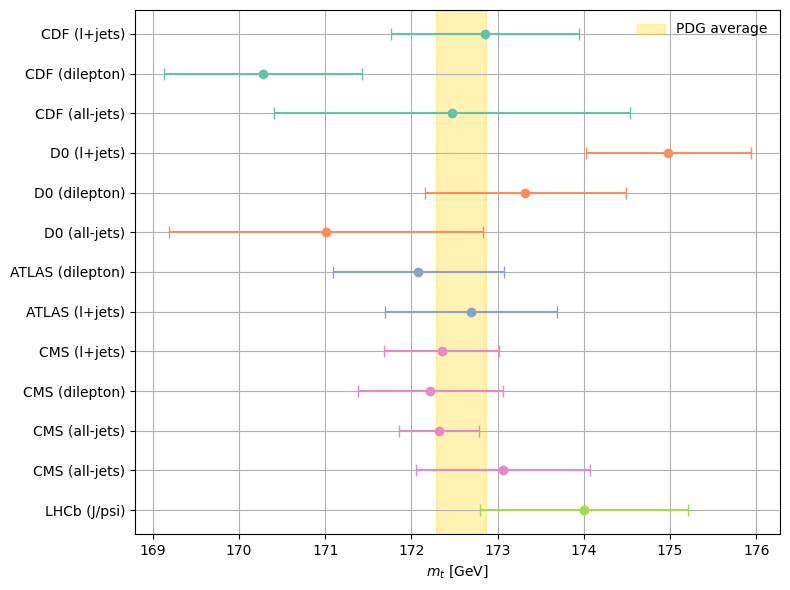

In [13]:
# Part F: worked example: the measurements and an "ideogram" plot
measurements = {
    "experiment": ["CDF", "CDF", "CDF", "D0", "D0", "D0",
                   "ATLAS", "ATLAS", "CMS", "CMS", "CMS", "CMS", "LHCb"],
    "channel":    ["l+jets", "dilepton", "all-jets", "l+jets", "dilepton", "all-jets",
                   "dilepton", "l+jets", "l+jets", "dilepton", "all-jets", "all-jets", "J/psi"],
    "mass_GeV":   [172.85, 170.28, 172.47, 174.98, 173.32, 171.01,
                   172.08, 172.69, 172.35, 172.22, 172.32, 173.06, 174.00],
    "stat_err":   [0.52, 0.76, 1.43, 0.58, 0.75, 1.16, 0.39, 0.48, 0.14, 0.72, 0.25, 0.84, 0.80],
    "syst_err":   [0.96, 0.86, 1.49, 0.76, 0.89, 1.41, 0.91, 0.88, 0.65, 0.44, 0.39, 0.56, 0.90],
}
top = pd.DataFrame(measurements)
top["total_err"] = np.hypot(top["stat_err"], top["syst_err"])
PDG_MT, PDG_MT_ERR = 172.57, 0.29                  # PDG 2024 direct-measurement average [GeV]

fig, ax = plt.subplots(figsize=(8, 6))
colours = dict(zip(top["experiment"].unique(), sns.color_palette("Set2")))
for i, r in top.iterrows():
    ax.errorbar(r.mass_GeV, i, xerr=r.total_err, fmt="o", capsize=4, color=colours[r.experiment])
ax.axvspan(PDG_MT - PDG_MT_ERR, PDG_MT + PDG_MT_ERR, color="gold", alpha=0.3, label="PDG average")
ax.set_yticks(range(len(top)))
ax.set_yticklabels([f"{r.experiment} ({r.channel})" for _, r in top.iterrows()])
ax.invert_yaxis()
ax.set_xlabel(r"$m_t$ [GeV]"); ax.legend(frameon=False); plt.tight_layout()

Plain mean = 172.5869 +/- 0.3292 GeV; median = 172.4700; std = 1.1869
Weighted mean = 172.5780 +/- 0.2502 GeV
Chi-square = 14.0261; ndf = 12; chi2/ndf = 1.1688
PDG scale factor = 1.0811; inflated uncertainty = 0.2705 GeV
experiment  channel  mass_GeV  total_err  weight_share
       CMS all-jets    172.32   0.463249      0.291652
       CMS   l+jets    172.35   0.664906      0.141571
       CMS dilepton    172.22   0.843801      0.087905


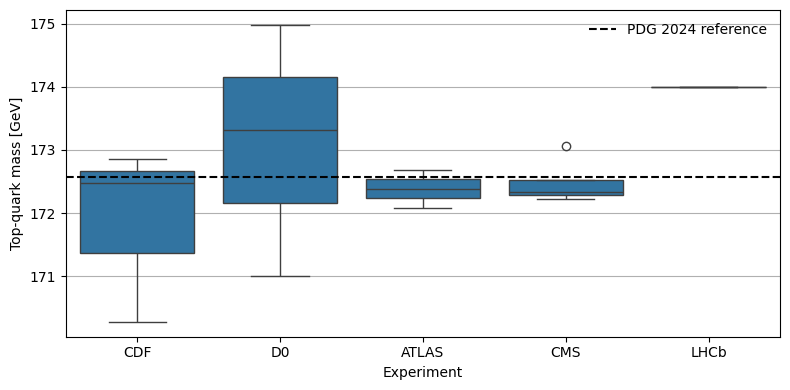

A box plot for LHCb has only one observation, so it provides no information about spread.


In [14]:
mass=top['mass_GeV'].to_numpy(); sigma=top['total_err'].to_numpy()
w=1/sigma**2
mean=mass.mean(); sem=stats.sem(mass); median=np.median(mass); sd=np.std(mass,ddof=1)
weighted=np.sum(w*mass)/np.sum(w)
weighted_err=1/np.sqrt(np.sum(w))
chi2=np.sum(w*(mass-weighted)**2);ndf=len(mass)-1
scale=max(1,np.sqrt(chi2/ndf));adjusted_err=weighted_err*scale
print(f'Plain mean = {mean:.4f} +/- {sem:.4f} GeV; median = {median:.4f}; std = {sd:.4f}')
print(f'Weighted mean = {weighted:.4f} +/- {weighted_err:.4f} GeV')
print(f'Chi-square = {chi2:.4f}; ndf = {ndf}; chi2/ndf = {chi2/ndf:.4f}')
print(f'PDG scale factor = {scale:.4f}; inflated uncertainty = {adjusted_err:.4f} GeV')
rank=top.copy();rank['weight_share']=w/w.sum()
print(rank.nlargest(3,'weight_share')[['experiment','channel','mass_GeV','total_err','weight_share']].to_string(index=False))
fig,ax=plt.subplots(figsize=(8,4))
sns.boxplot(data=top,x='experiment',y='mass_GeV',ax=ax)
ax.axhline(PDG_MT,ls='--',color='black',label='PDG 2024 reference')
ax.set(xlabel='Experiment',ylabel='Top-quark mass [GeV]');ax.legend(frameon=False)
fig.tight_layout();fig.savefig(OUT/'lab02_top_mass_boxplot.pdf');plt.show()
print('A box plot for LHCb has only one observation, so it provides no information about spread.')

**Check your understanding (F):** Why do the plain mean and the weighted mean differ? Which measurement dominates, and why? Our weighted error is smaller than the PDG's ±0.29 GeV: what did our simple combination ignore?

*Your answer:* The ordinary mean weights each input equally, whereas the inverse-variance mean assigns more weight to measurements with smaller quoted uncertainties. The dominating entry is identified by the printed `weight_share` ranking; it dominates because its combined uncertainty is smallest. The simple uncertainty ignores correlated systematics, experiment-to-experiment covariance, nontrivial measurement dependence and the full PDG combination procedure; it should not be treated as an improvement over the PDG average.

## Exit task (~5 min)

1. Make sure every cell runs from top to bottom (Kernel → Restart & Run All).
2. Check that `outputs/` contains: `my_dimuon_extract.npz`, `lab02_dimuon_spectrum.pdf`, `lab02_z_estimate.json`.
3. Commit and push the notebook and `outputs/`. Pset 1 is released this week.
4. Submit the commit SHA (`git log -1 --format=%H`) on Moodle (this step can be done after class).

In [15]:
# Exit task: commit and push from the terminal:
#   git add lab02_*.ipynb outputs/
#   git commit -m "Lab 02"
#   git push
for f in ["my_dimuon_extract.npz", "lab02_dimuon_spectrum.pdf", "lab02_z_estimate.json"]:
    print(f"{f:28s}", "OK" if (OUT / f).exists() else "MISSING")

my_dimuon_extract.npz        MISSING
lab02_dimuon_spectrum.pdf    MISSING
lab02_z_estimate.json        MISSING


## Further reading

- L. Lista, *Statistical Methods for Data Analysis in Particle Physics*, 3rd ed. (2023): descriptive statistics and combination of measurements
- ROOT Primer: https://root.cern/primer/ · PyROOT manual: https://root.cern/manual/python/
- RDataFrame tutorials (see `df102_NanoAODDimuonAnalysis`, which this lab follows): https://root.cern/doc/master/group__tutorial__dataframe.html
- CMS Open Data portal: https://opendata.cern.ch
- PDG review, top quark: https://pdg.lbl.gov
- mplhep (HEP-style Matplotlib): https://github.com/scikit-hep/mplhep